# <center> Regional Solar Energy Potential Analysis</center>



## Visualizing Solar Irradiance Data



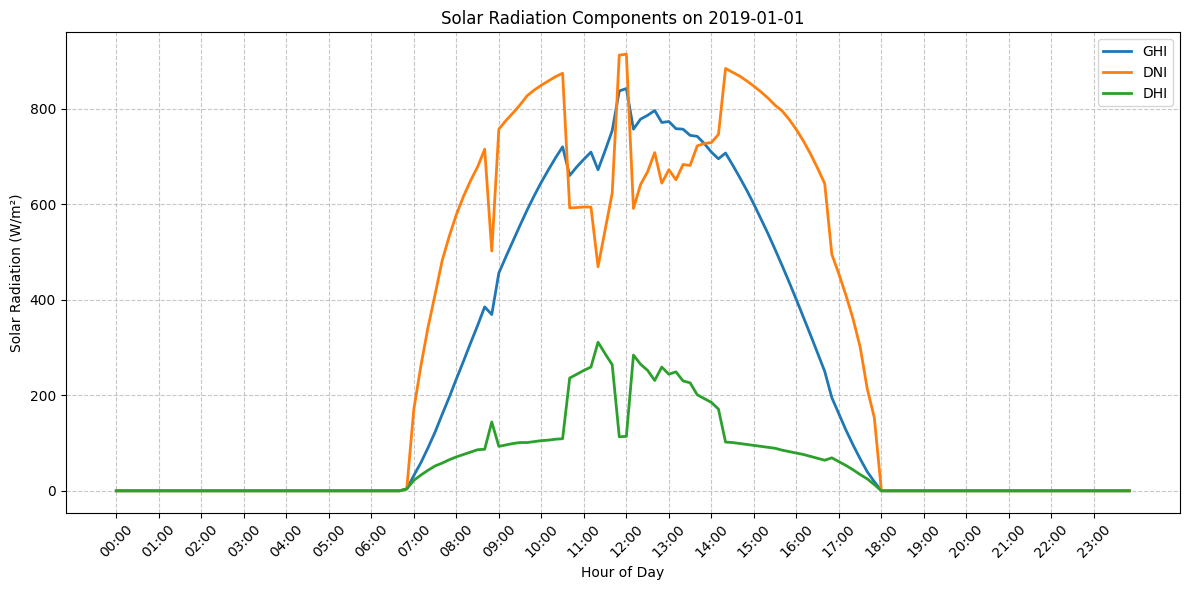

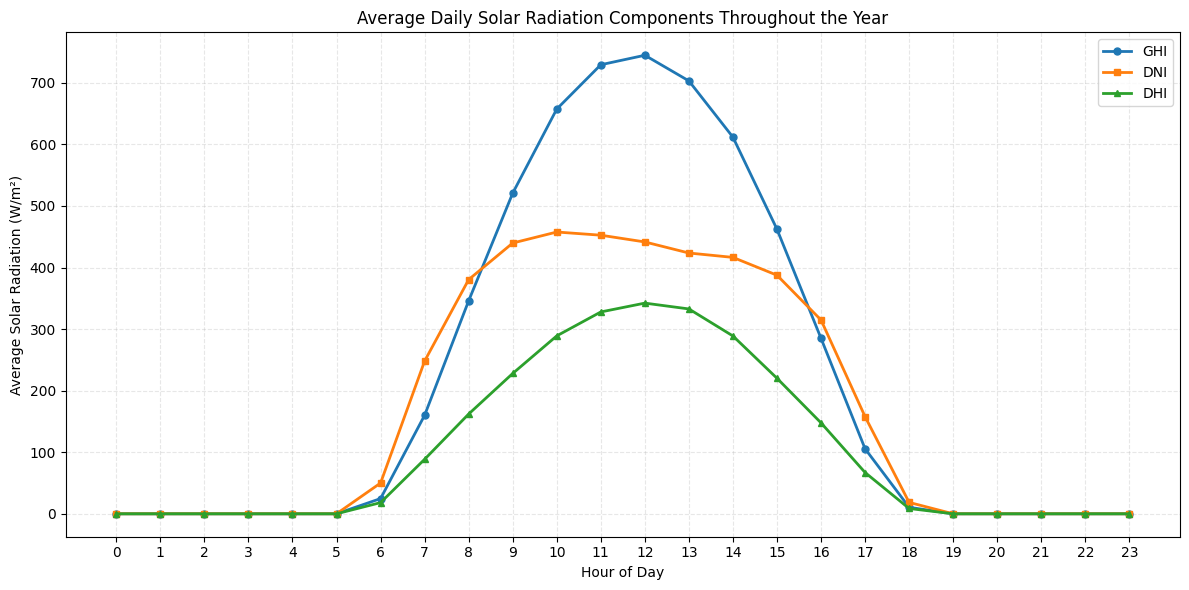

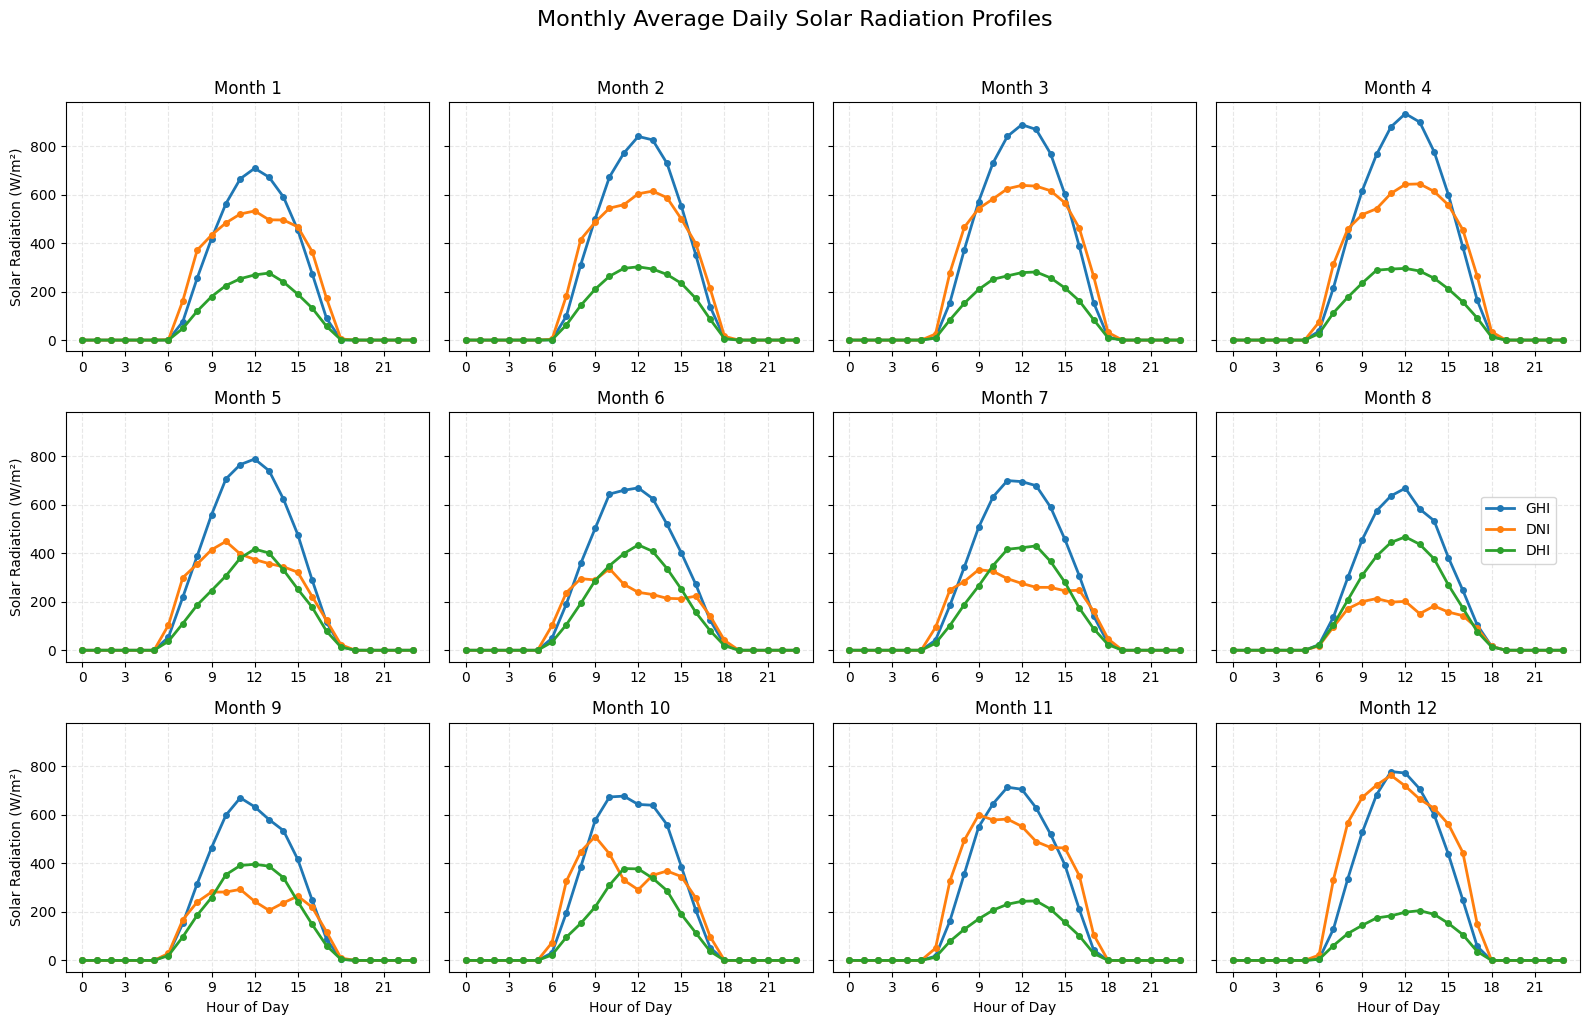

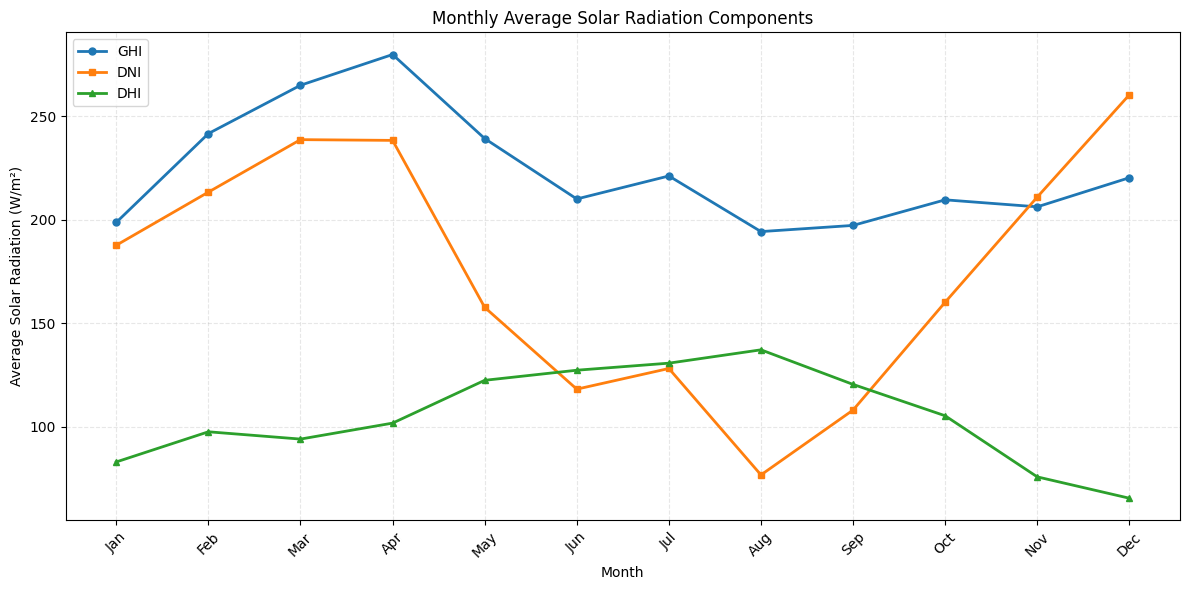

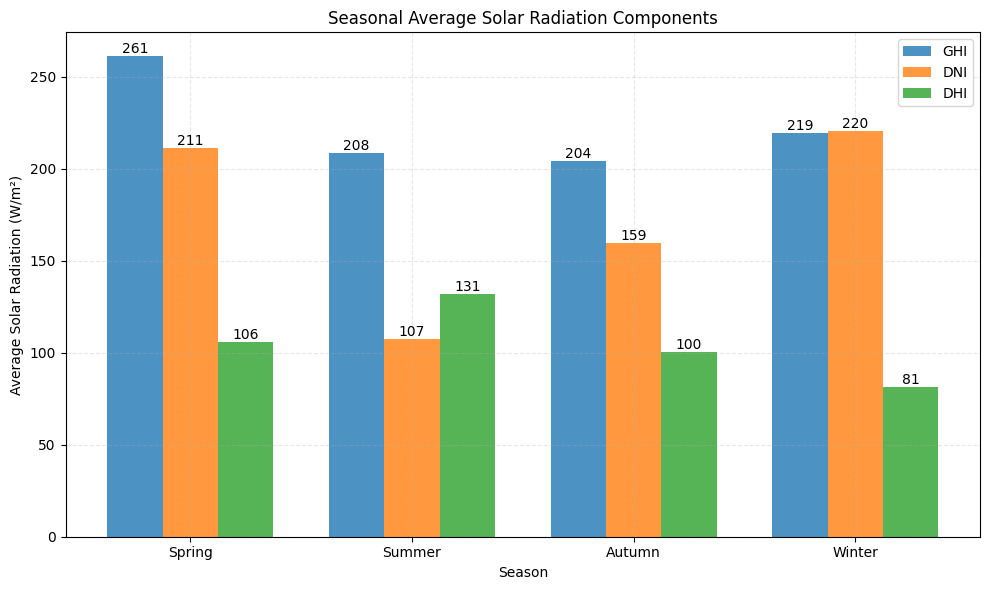

In [1]:
import weather_visualization as swv
import matplotlib.pyplot as plt
import os
%matplotlib inline

# Choose your city
city_name = 'Bangkok'
year = '2019'

# Load weather data
weather = swv.read_weather(os.path.join('./weather_data', f'{city_name}_weather.csv'))

# Visualize data for a specific day
# Here, we use the first day in the dataset as an example, but you can modify it to other dates
first_date = '2019-01-01'
swv.plot_single_day(weather, first_date)
plt.show()

# Visualize the average daily data for the entire year
swv.plot_daily_avg(weather)
plt.show()

# Visualize the average data for each month
swv.plot_monthly_avg(weather)
plt.show()

# Visualize the hourly data for each month
swv.plot_monthly_hourly(weather)
plt.show()

# Visualize seasonal data
swv.plot_seasonal(weather)
plt.show()

## POA Calculation and Visualization

/var/folders/wc/1xdjgq_x17ldscyry9fzbc180000gp/T/ipykernel_2941/97444613.py:14: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  latitude = buildings.geometry.centroid.y.mean()
/var/folders/wc/1xdjgq_x17ldscyry9fzbc180000gp/T/ipykernel_2941/97444613.py:15: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  longitude = buildings.geometry.centroid.x.mean()


No data for the specified date!


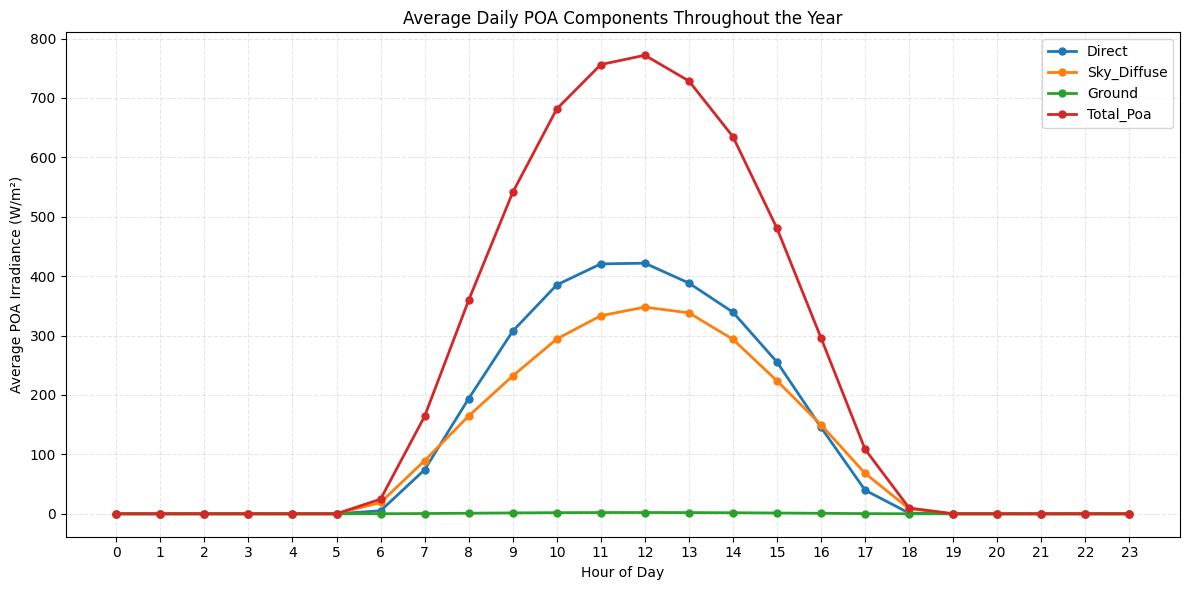

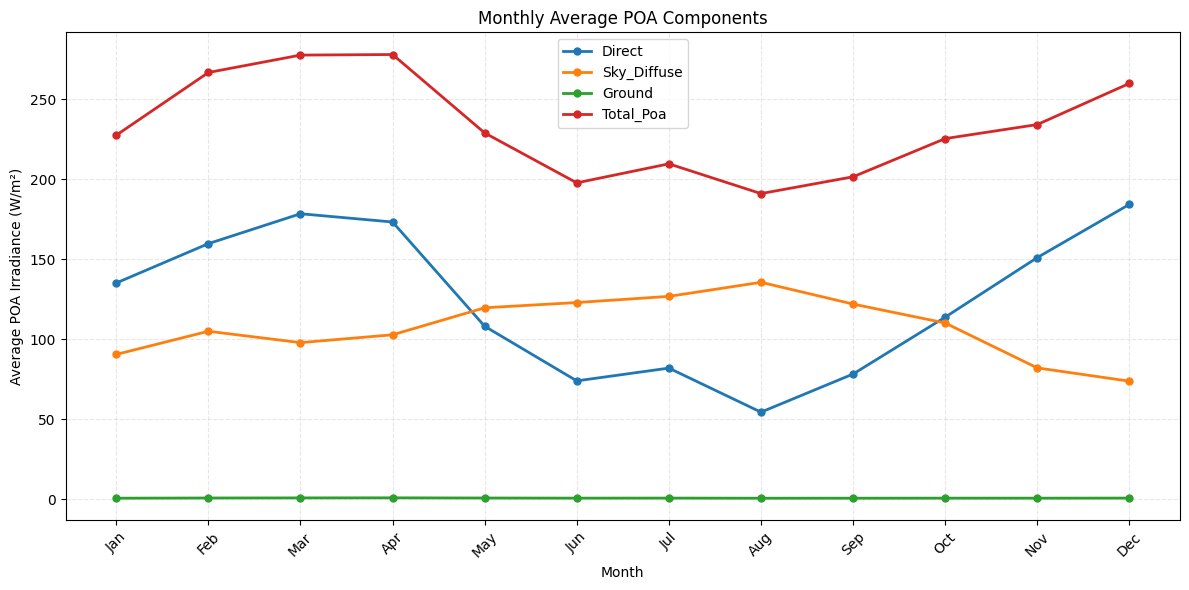

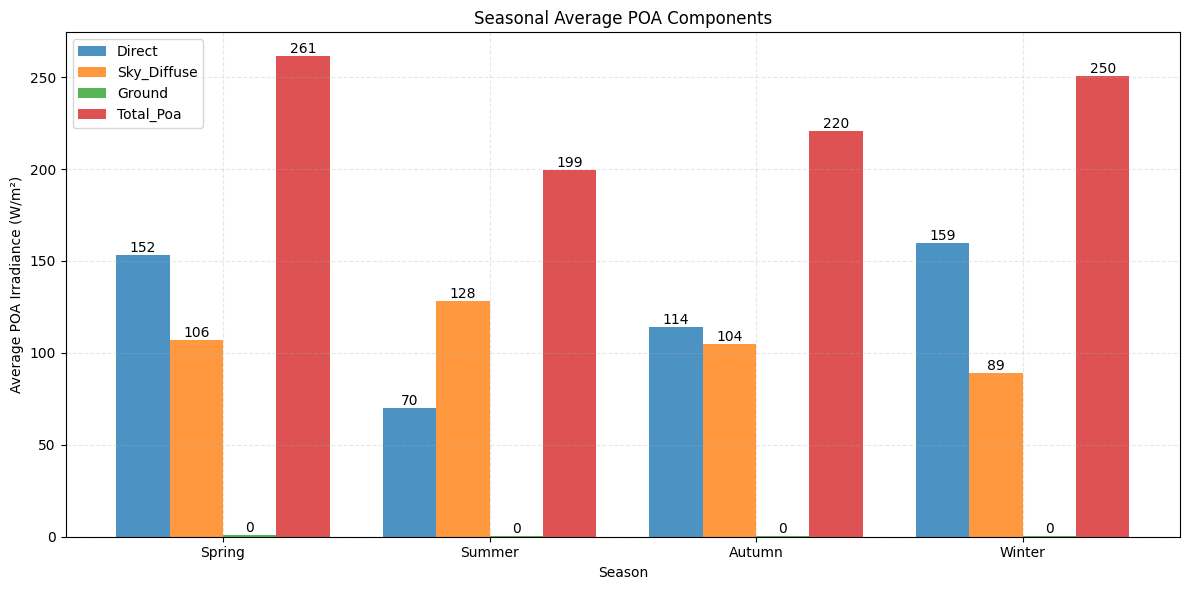

In [2]:
from poa_calculation import calculate_poa, calculate_poa_track
from poa_visualization import *
import geopandas as gpd
import pandas as pd

# Load weather data for Shenzhen
weather = swv.read_weather(os.path.join('./weather_data', f'{city_name}_weather.csv'))

# Load building data for Shenzhen
buildings = gpd.read_file(os.path.join('./buildings_data', f'{city_name}_building.geojson'))

# Calculate the mean latitude and longitude of the buildings' centroids
# This is done to get a representative location for the POA calculation
latitude = buildings.geometry.centroid.y.mean()
longitude = buildings.geometry.centroid.x.mean()

# Determine the surface azimuth based on the latitude
# For locations north of the equator, the surface azimuth is set to 180 degrees
# For locations south of the equator, the surface azimuth is set to 0 degrees
if latitude > 0:
    surface_azimuth = 180
else:
    surface_azimuth = 0

# Calculate the Plane of Array (POA) irradiance for a fixed system
poa_fixed = calculate_poa(weather, latitude, surface_azimuth, latitude, longitude)

# Calculate the POA irradiance for a dual-axis tracking system
poa_track = calculate_poa_track(weather, latitude, longitude)

# Convert the calculated POA data into DataFrames for easier manipulation
poa_df_fixed = pd.DataFrame(poa_fixed)
poa_df_tracked = pd.DataFrame(poa_track)


# Save the POA data for both fixed and tracked systems to CSV files
poa_df_fixed.to_csv(os.path.join('./result', f'{city_name}_poa_fixed_results.csv'), index=False)
poa_df_tracked.to_csv(os.path.join('./result', f'{city_name}_poa_tracked_results.csv'), index=False)

# Visualize the POA components for a specific day (January 1st, 2020)
plot_poa_single_day(poa_df_fixed, '2020-01-01')
plt.show()

# Visualize the annual average daily POA change
plot_poa_daily_avg(poa_df_fixed)
plt.show()

# Visualize the monthly POA change
plot_poa_monthly_avg(poa_df_fixed)
plt.show()

# Visualize the seasonal POA change
plot_poa_seasonal(poa_df_fixed)
plt.show()

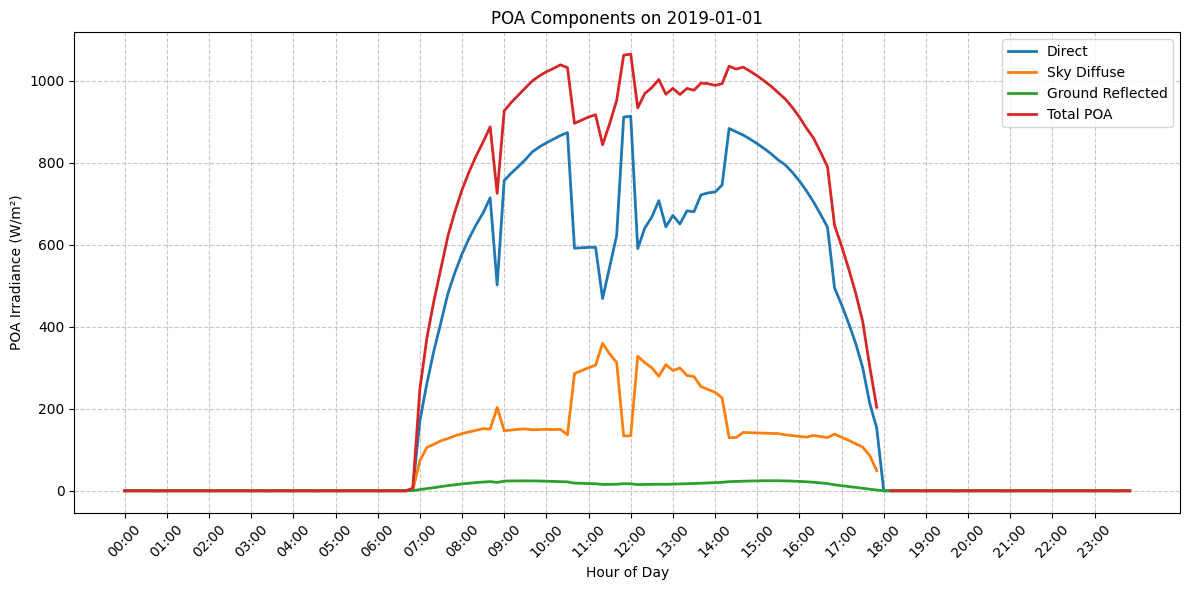

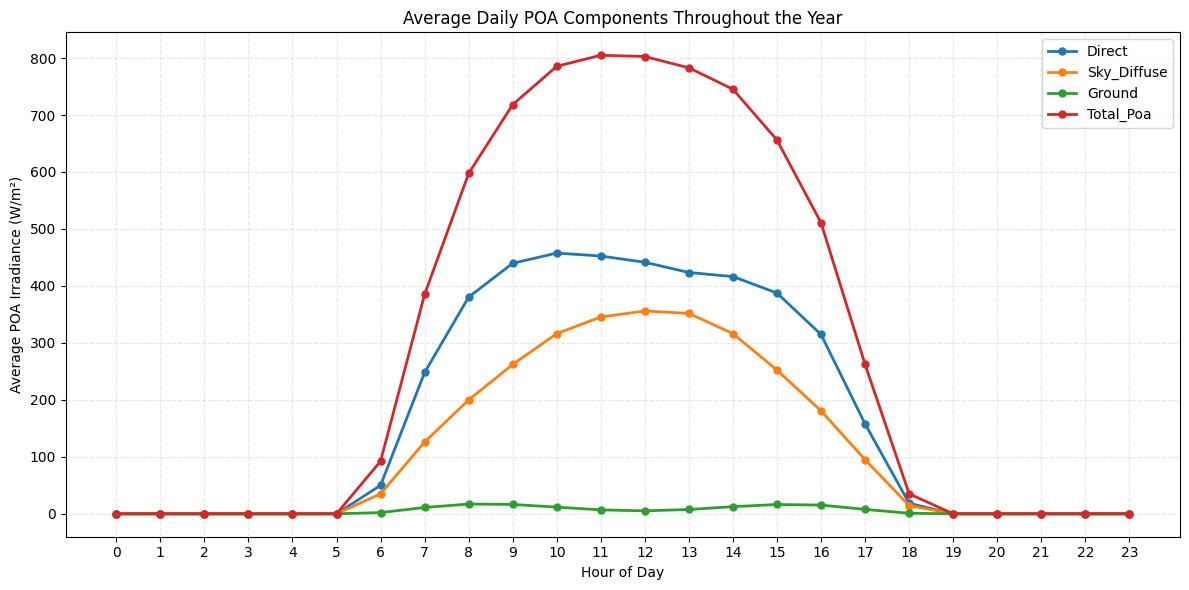

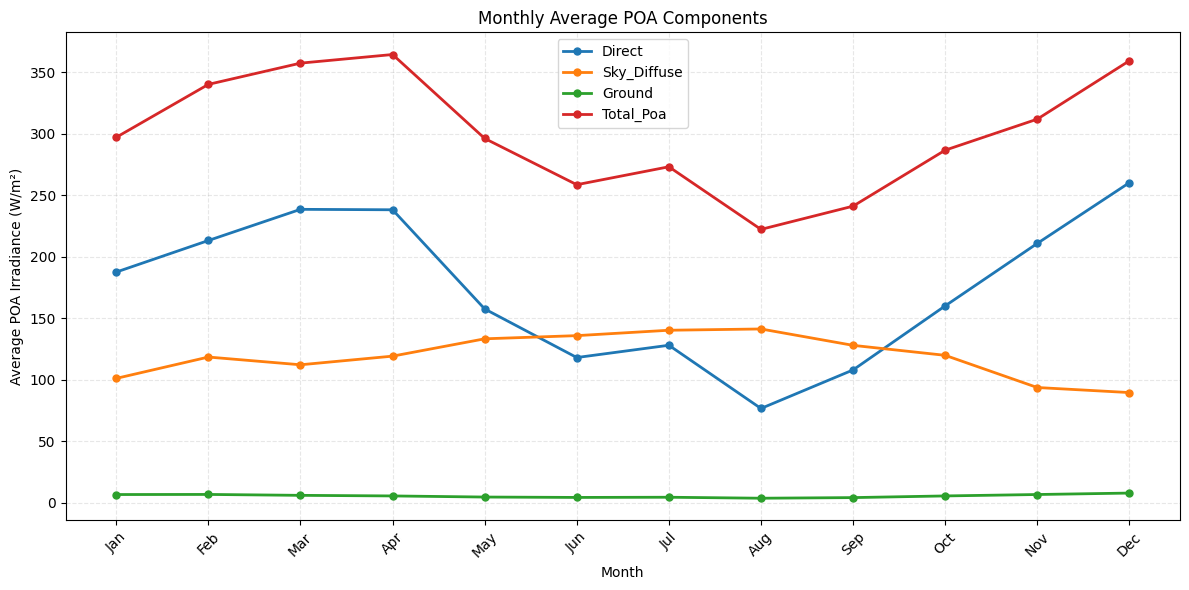

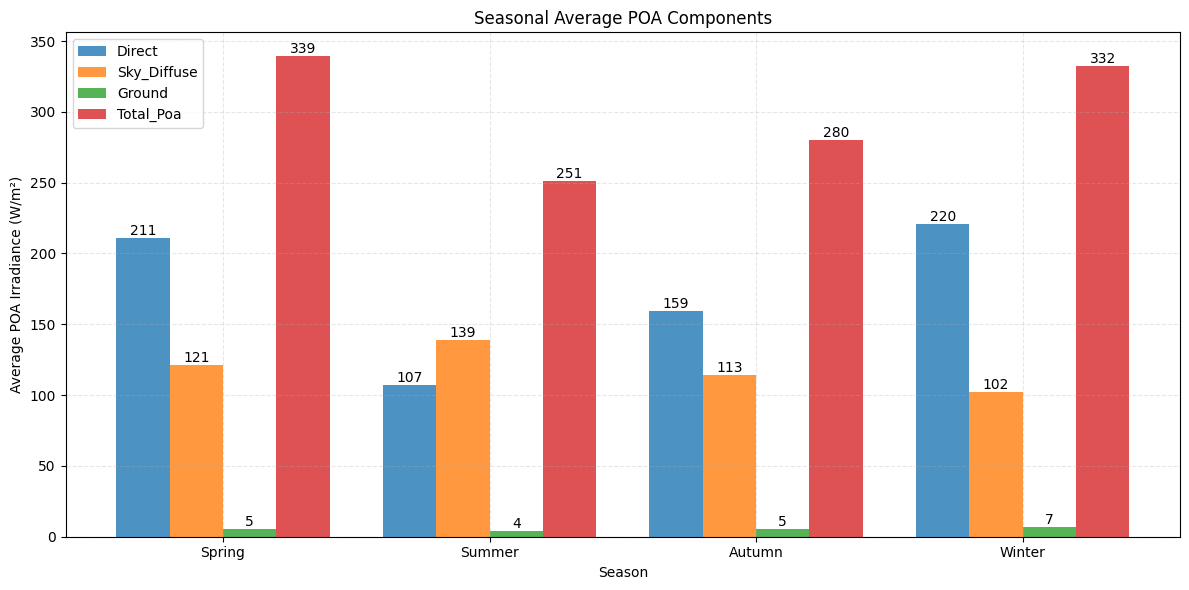

In [3]:
# Plotting the POA for a single day for the tracked system
plot_poa_single_day(poa_df_tracked, f'{year}-01-01')
plt.show()

# Plotting the annual average daily POA change for the tracked system
plot_poa_daily_avg(poa_df_tracked)
plt.show()

# Plotting the monthly POA change for the tracked system
plot_poa_monthly_avg(poa_df_tracked)
plt.show()

# Plotting the seasonal POA change for the tracked system
plot_poa_seasonal(poa_df_tracked)
plt.show()

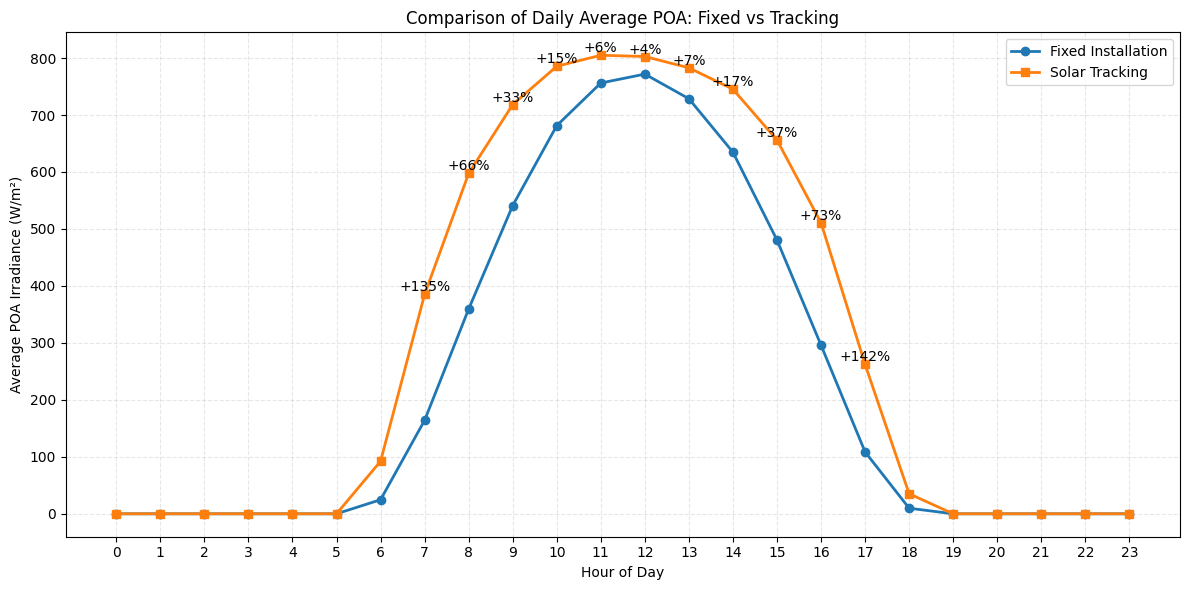

In [4]:
# Importing the function to compare daily POA for fixed and tracked systems
from poa_visualization import compare_fixed_tracked_daily
# Calling the function to compare daily POA for fixed and tracked systems
compare_fixed_tracked_daily(poa_df_fixed, poa_df_tracked)

## PV Output Calculation and Visualization


In [5]:
# Importing the function to calculate PV efficiency with rounding
from Efficiency_calculation import calculate_pv_efficiency_round

# Defining the module parameters for the calculation
module_parameters = {
    'gamma_ref': 1,  # Reference temperature coefficient of the current
    'mu_gamma': 0.002,  # Temperature coefficient of the current
    'I_L_ref': 7.3,  # Reference light-generated current
    'I_o_ref': 1e-10,  # Reverse saturation current
    'R_sh_ref': 400,  # Reference shunt resistance
    'R_s': 0.3,  # Series resistance
    'R_sh_0': 3000,  # Shunt resistance at zero irradiance
    'cells_in_series': 60,  # Number of cells in series
    'alpha_sc': 0.004,  # Temperature coefficient of the short-circuit current
    'EgRef': 1.12,  # Reference bandgap energy
    'irrad_ref': 1000,  # Reference irradiance
    'temp_ref': 25  # Reference temperature
}

# Calculating the PV output for the fixed system
pvout_result_fixed = calculate_pv_efficiency_round(
    poa_data=poa_df_fixed,  # Plane of Array data for the fixed system
    weather_data=weather,  # Weather data
    module_area=1.69,  # Module area
    module_parameters=module_parameters  # Module parameters defined above
)

# Calculating the PV output for the tracked system
pvout_result_tracked = calculate_pv_efficiency_round(
    poa_data=poa_df_tracked,  # Plane of Array data for the tracked system
    weather_data=weather,  # Weather data
    module_area=1.69,  # Module area
    module_parameters=module_parameters  # Module parameters defined above
)

# Saving the results for the fixed system to a CSV file
pvout_result_fixed.to_csv(os.path.join('./result', f'{city_name}_efficiency_results.csv'), index=False)

# Saving the results for the tracked system to a CSV file
pvout_result_tracked.to_csv(os.path.join('./result', f'{city_name}_efficiency_results_tracked.csv'), index=False)

/opt/anaconda3/envs/mini-2025/lib/python3.12/site-packages/pvlib/pvsystem.py:2475: pvlibDeprecationWarning: 
The pvlib.pvsystem.singlediode parameter ivcurve_pnts was deprecated in pvlib 0.10.0 and will be removed in 0.11.0. Use pvlib.pvsystem.v_from_i and pvlib.pvsystem.i_from_v instead.
  warn_deprecated('0.10.0', name='pvlib.pvsystem.singlediode',
/opt/anaconda3/envs/mini-2025/lib/python3.12/site-packages/pvlib/pvsystem.py:2475: pvlibDeprecationWarning: 
The pvlib.pvsystem.singlediode parameter ivcurve_pnts was deprecated in pvlib 0.10.0 and will be removed in 0.11.0. Use pvlib.pvsystem.v_from_i and pvlib.pvsystem.i_from_v instead.
  warn_deprecated('0.10.0', name='pvlib.pvsystem.singlediode',


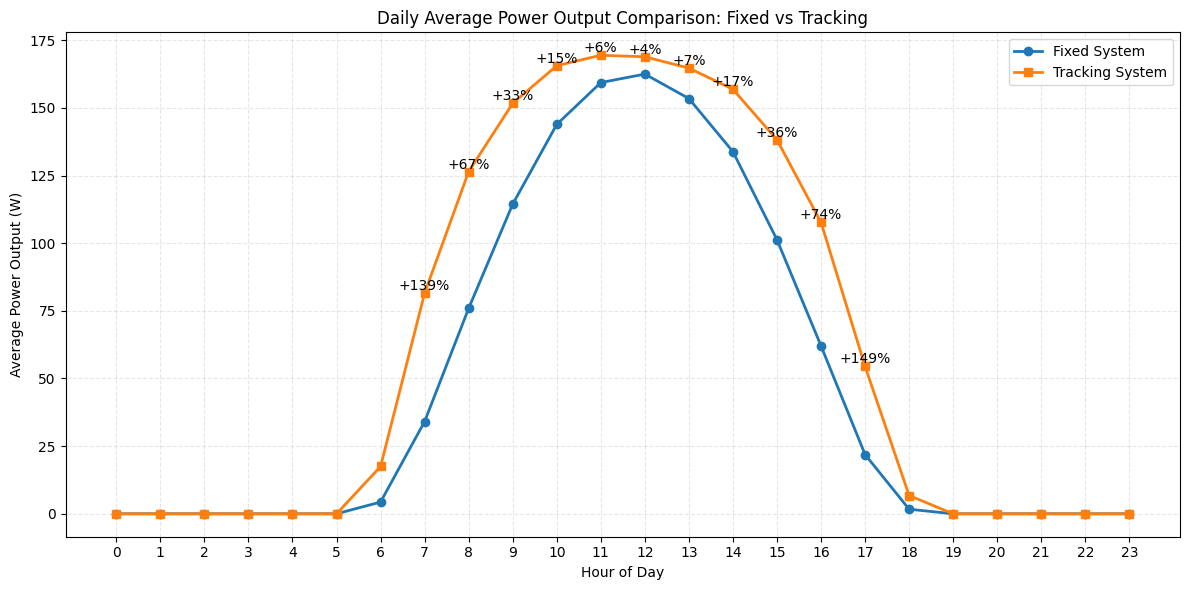

In [6]:
# Importing the function to plot daily PV power output
from poa_visualization import *
# Plotting the daily PV power output for both fixed and tracked systems
plot_pv_power_daily(pvout_result_fixed, pvout_result_tracked)

## Building Rooftop Solar Potential Assessment and Visualization


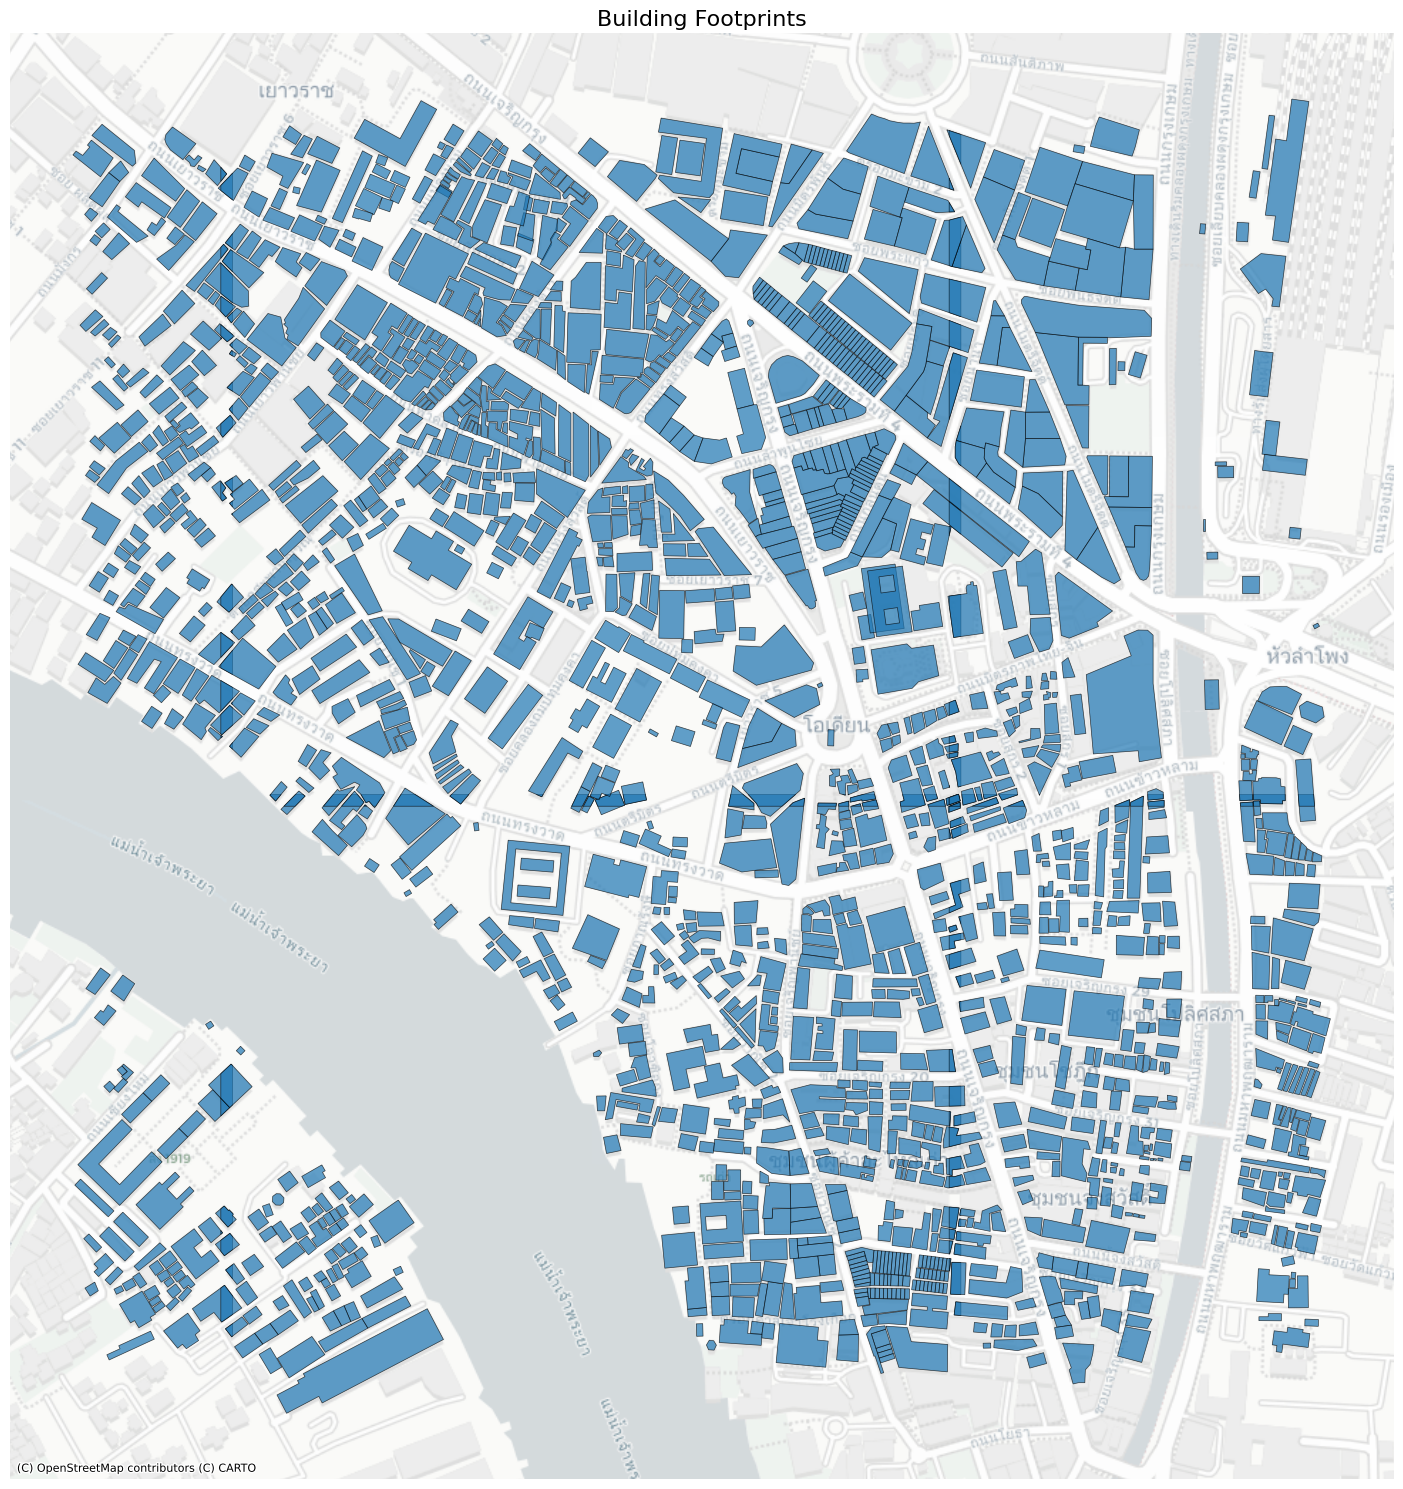

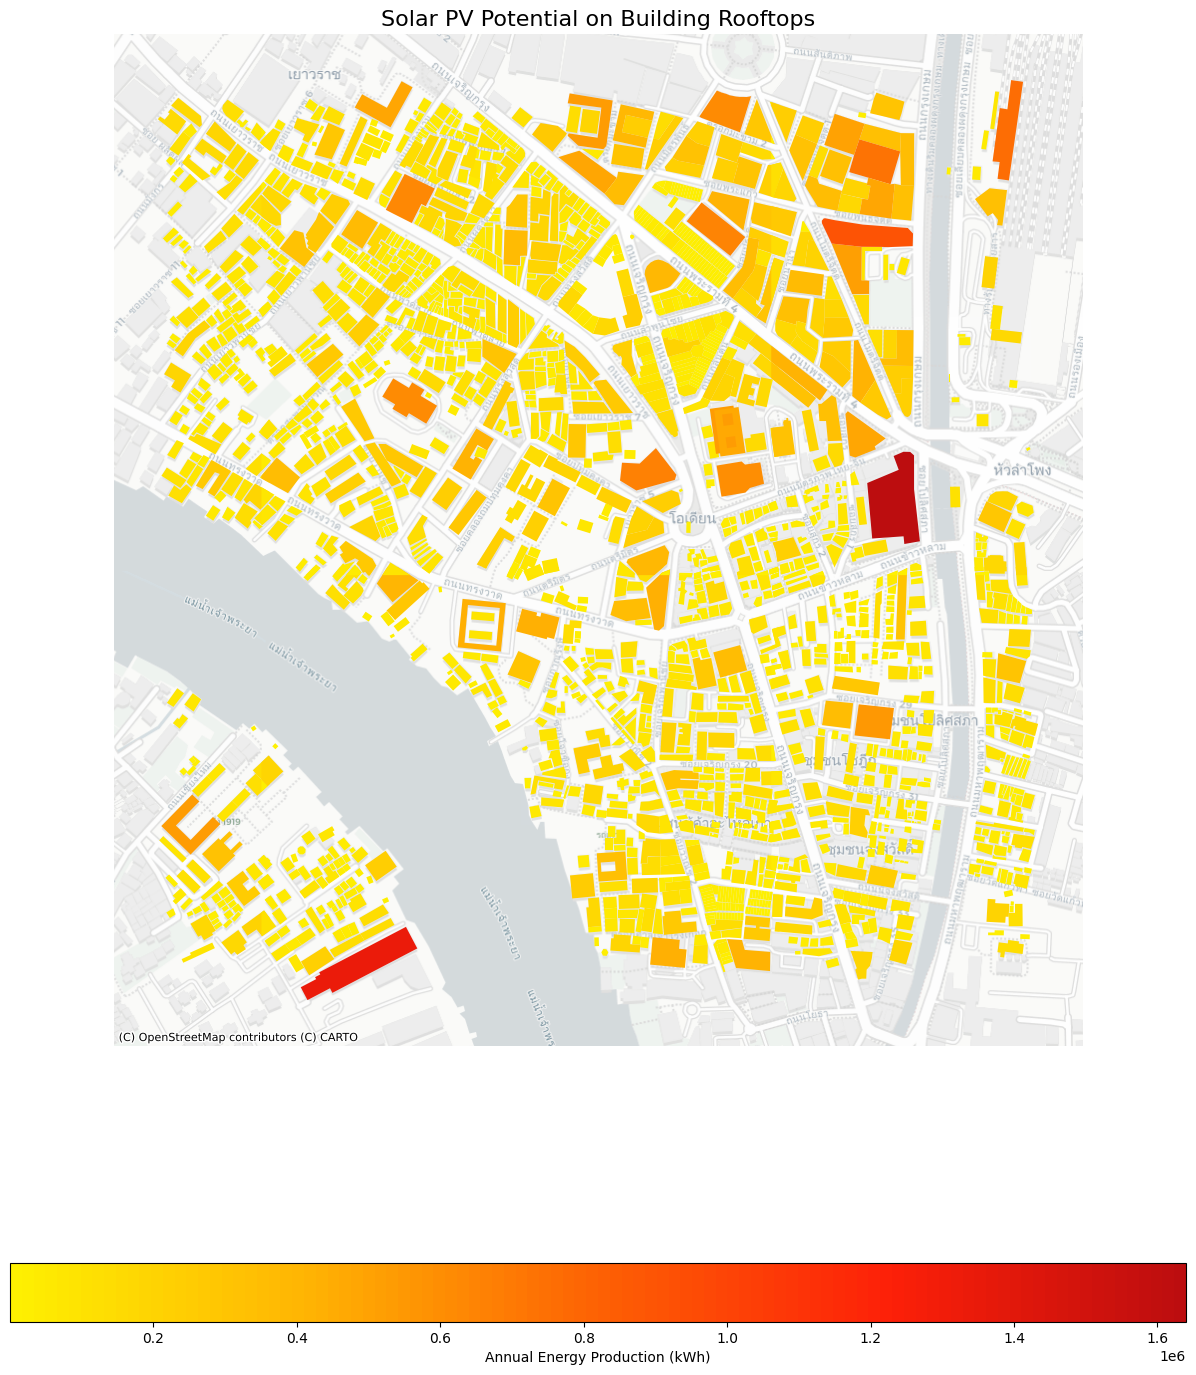

In [7]:
# Importing the necessary module for building PV potential analysis
from building_pv_potential import * 
# Importing pandas for data manipulation and analysis
import pandas as pd

# Defining the path to the GeoJSON file containing building data
geojson_path = os.path.join('./buildings_data', f'{city_name}_building.geojson')
# Visualizing the buildings using the provided GeoJSON path
buildings = visualize_buildings(geojson_path)

# Displaying the plot
plt.show()

# Calculating the PV potential for each building
buildings = calculate_pv_potential(buildings, pvout_result_fixed)

# Visualizing the PV potential of each building
visualize_pv_potential(buildings)
# Displaying the plot
plt.show()

# Creating statistical charts for further analysis


(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'Annual PV Potential for Building 8'}, xlabel='Month', ylabel='Daily Energy Production (kWh)'>)

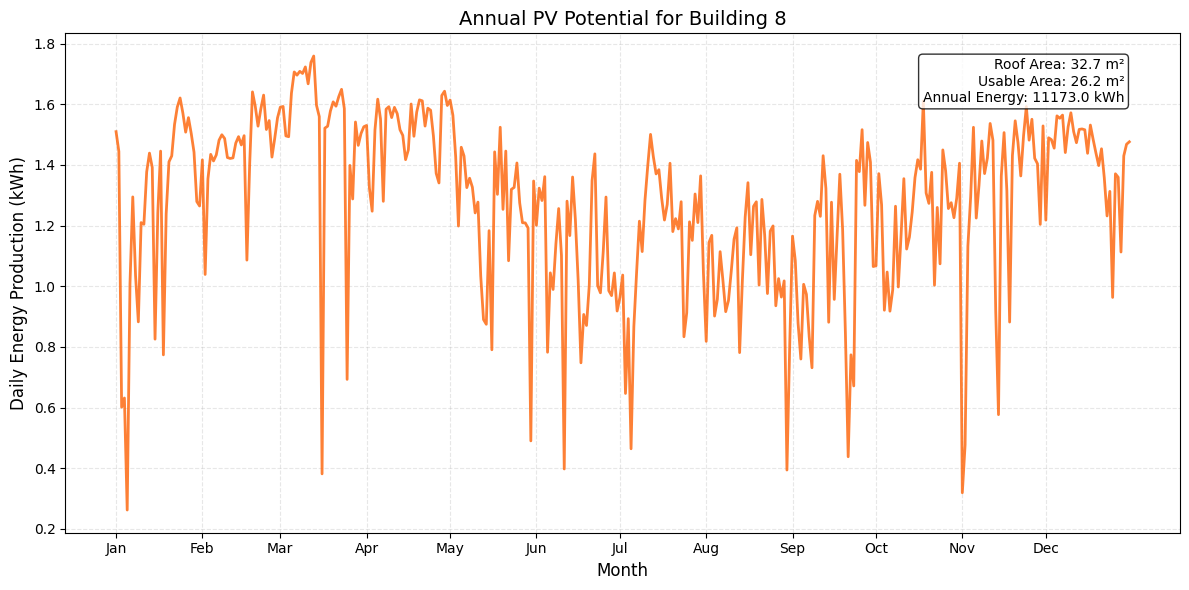

In [8]:
# Assuming the usable space ratio of the roof to be 0.8
visualize_building_annual_pv(buildings, 8, pvout_result_fixed)